In [ ]:
######################################################################
##  H-HT                                                            ##
##                                                                  ##
##                                          ##
######################################################################


In [13]:
import pandas as pd
descrip = pd.read_csv('PaDEL_descriptors.csv')
print(descrip.shape)

df = pd.read_excel("FINAL.xlsx")
df = df.dropna(subset=['SMILES']) 
print(df.shape)

(2856, 881)
(2856, 22)


In [9]:
df.head()

,COUNT,cid,SMILES,MW_pub,ck pub,VERIFY,Unnamed: 6,ck_swis,MW_swis,ESOL Class,...,Unnamed: 12,CK_AD,MW_AD,caco2,hia,BBB,hERG,hERG-10um,Ames,H-HT
0,1,145991278.0,C1[C@]2(C3=CC(=NC=C3OC4=C2C=C(C=C4)C5=NC(=CC=C...,443.4,443,True,NaN,443.0,443.41,Moderately soluble,...,NaN,443.0,443.12,-4.881416,0.000000,0.001933,0.909164,0.717378,0.947849,0.989082
1,2,145990468.0,CC#CC1=CC(=CN=C1)C2=CC3=C(C=C2)OC4=CN=C(C=C4[C...,463.5,463,True,NaN,463.0,463.46,Moderately soluble,...,NaN,463.0,463.14,-4.828875,0.000000,0.000030,0.942825,0.776856,0.794406,0.988022
2,3,122172743.0,CN1C(NC2(C1=O)C3=C(C=CC(=C3)OCC(F)(F)F)OC24CCC...,447.4,447,True,NaN,447.0,447.45,Moderately soluble,...,NaN,447.0,447.18,-5.399611,0.000046,0.969402,0.755374,0.757735,0.426495,0.804849
3,4,145983198.0,CC#CC1=CC(=CN=C1)C2=CC3=C(C=C2)OC4=CN=C(C=C4[C...,450.5,450,True,NaN,450.0,450.49,Moderately soluble,...,NaN,450.0,450.17,-4.864286,0.000006,0.004028,0.885521,0.696834,0.734198,0.973429
4,5,45254510.0,CC1(COC1)C#CC2=CC3=C(N=C2)OC4=C([C@@]35COC(=N5...,442.4,442,True,NaN,442.0,442.44,Moderately soluble,...,NaN,442.0,442.14,-4.885711,0.000002,0.698582,0.770069,0.598314,0.942510,0.976820


In [15]:
# H-HT

X = descrip.copy()
y = df['H-HT'].values
y


array([0.98908222, 0.98802185, 0.80484903, ..., 0.93502015, 0.88316178,
       0.79903847])

In [16]:
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import train_test_split

# 1. Load data
descrip = pd.read_csv("PaDEL_descriptors.csv")
df = pd.read_excel("FINAL.xlsx")

# 2. Drop rows with missing SMILES values in the main sheet
df = df.dropna(subset=["SMILES"])

# 3. CRITICAL ALIGNMENT: Align rows by resetting indices
# This guarantees row 0 of features matches row 0 of targets perfectly
df = df.reset_index(drop=True)
descrip = descrip.reset_index(drop=True)

# 4. Prepare X and y
# Drop the text tracking column 'Name' from PaDEL if it's there
if "Name" in descrip.columns:
    X = descrip.drop(columns=["Name"])
else:
    X = descrip.copy()

# Force convert all features to numbers and handle any blank values safely
X = X.apply(pd.to_numeric, errors="coerce")
X = X.fillna(X.mean())

# Isolate the target vector for Human Hepatotoxicity
y = df["H-HT"].values

print(f"Features matrix shape (X): {X.shape}")
print(f"Target vector shape (y): {y.shape}")

# ==========================================
# 5. SPLIT DATA & TRAIN MODEL
# ==========================================
# Split into 80% training data and 20% validation test data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(f"Training on {X_train.shape[0]} compounds...")
model = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
model.fit(X_train, y_train)

# ==========================================
# 6. EVALUATE PERFORMANCE
# ==========================================
y_pred = model.predict(X_test)

print("\n=== H-HT QSAR MODEL METRICS ===")
print(f"Mean Squared Error (MSE): {mean_squared_error(y_test, y_pred):.4f}")
print(f"R² Score (Variance Explained): {r2_score(y_test, y_pred):.4f}")

Features matrix shape (X): (2856, 881)
Target vector shape (y): (2856,)
Training on 2284 compounds...

=== H-HT QSAR MODEL METRICS ===
Mean Squared Error (MSE): 0.0006
R² Score (Variance Explained): 0.8501


In [25]:
import pandas as pd
import lazypredict.Supervised
from lazypredict.Supervised import LazyRegressor
from sklearn.model_selection import train_test_split

# ==========================================
# 1. EXCLUDE SPECIFIC MODELS FROM LAZYPREDICT
# ==========================================
# List of model names exactly as they appear in the LazyPredict output table
models_to_ignore = [
    "Lars",
    "GaussianProcessRegressor",
    "KernelRidge",
    "MLPRegressor",
    "DummyRegressor",
    "Lasso",
    "ElasticNet",
]

# Filter LazyPredict's internal regressor registry dynamically
lazypredict.Supervised.REGRESSORS = [
    (name, model)
    for name, model in lazypredict.Supervised.REGRESSORS
    if name not in models_to_ignore
]


# ==========================================
# 2. RUN LAZYREGRESSOR (WITHOUT THE IGNORED MODELS)
# ==========================================
# Load your data
descrip = pd.read_csv("PaDEL_descriptors.csv")
df = pd.read_excel("FINAL.xlsx").dropna(subset=["SMILES"])

df = df.reset_index(drop=True)
descrip = descrip.reset_index(drop=True)

X = descrip.drop(columns=["Name"]) if "Name" in descrip.columns else descrip.copy()
X = X.apply(pd.to_numeric, errors="coerce").fillna(X.mean())
y = df["H-HT"].values

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(
    f"Running LazyRegressor. Ignored {len(models_to_ignore)} unstable/slow models..."
)

# Initialize and fit
reg = LazyRegressor(verbose=0, ignore_warnings=True, custom_metric=None)
models, predictions = reg.fit(X_train, X_test, y_train, y_test)

# View clean, optimized results table
print(models)

High-dimensional dataset (881 features). Some models may be slow or fail. Consider dimensionality reduction.


Running LazyRegressor. Ignored 7 unstable/slow models...
                               Adjusted R-Squared     R-Squared          RMSE  \
Model                                                                           
SGDRegressor                         2.629306e+26 -1.427469e+26  7.709002e+11   
QuantileRegressor                    3.055721e+00 -1.160660e-01  6.816473e-02   
SVR                                  2.911291e+00 -3.765382e-02  6.572658e-02   
LassoLars                            2.845598e+00 -1.988318e-03  6.458715e-02   
PassiveAggressiveRegressor           2.462620e+00  2.059328e-01  5.749677e-02   
LarsCV                               2.216519e+00  3.395432e-01  5.243690e-02   
AdaBoostRegressor                    2.088494e+00  4.090489e-01  4.960102e-02   
RANSACRegressor                      1.992330e+00  4.612569e-01  4.735934e-02   
LinearSVR                            1.818267e+00  5.557570e-01  4.300561e-02   
LassoLarsCV                          1.694867e+00  6

In [ ]:
# I have to exclude the SGDRegressor
models

,Adjusted R-Squared,R-Squared,RMSE,Time Taken
Model,,,,
SGDRegressor,2.629306e+26,-1.427469e+26,7.709002e+11,0.179001
QuantileRegressor,3.055721e+00,-1.160660e-01,6.816473e-02,1.304785
SVR,2.911291e+00,-3.765382e-02,6.572658e-02,0.288661
LassoLars,2.845598e+00,-1.988318e-03,6.458715e-02,0.200000
PassiveAggressiveRegressor,2.462620e+00,2.059328e-01,5.749677e-02,0.313075
LarsCV,2.216519e+00,3.395432e-01,5.243690e-02,1.953833
AdaBoostRegressor,2.088494e+00,4.090489e-01,4.960102e-02,0.626777
RANSACRegressor,1.992330e+00,4.612569e-01,4.735934e-02,14.656170
LinearSVR,1.818267e+00,5.557570e-01,4.300561e-02,2.394322


In [27]:
import matplotlib.pyplot as plt
import seaborn as sns


def plot_lazy_metrics(df_models, metric="R-Squared"):
    """Plots horizontal bar charts for LazyRegressor metrics with automatic

    filtering and sorting.

    Parameters:
    - df_models: The DataFrame returned by LazyRegressor (e.g., `models`)
    - metric: 'R-Squared', 'RMSE', or 'Time Taken'
    """
    sns.set_theme(style="whitegrid")
    plt.figure(figsize=(7, 10))

    # Make a copy to prevent modifying the original DataFrame variables
    df_plot = df_models.copy()

    # Apply structural safety filters for baseline linear models that blew up
    if "R-Squared" in df_plot.columns:
        df_plot = df_plot[df_plot["R-Squared"] > 0]

    # Handle metric-specific plotting parameters
    if metric == "R-Squared":
        df_plot = df_plot.sort_values(by="R-Squared", ascending=False)
        ax = sns.barplot(
            y=df_plot.index, x="R-Squared", data=df_plot, palette="viridis"
        )
        ax.set(xlim=(0, 1.05))
        plt.title("H-HT QSAR Baseline Performance ($R^2$ Score)", fontsize=13)
        plt.xlabel("$R^2$ Value (Higher is Better)", fontsize=11)

    elif metric == "RMSE":
        df_plot = df_plot.sort_values(by="RMSE", ascending=True)
        ax = sns.barplot(
            y=df_plot.index, x="RMSE", data=df_plot, palette="mako"
        )
        max_rmse = df_plot["RMSE"].max() if not df_plot.empty else 1.0
        ax.set(xlim=(0, max_rmse * 1.1))
        plt.title(
            "H-HT QSAR Baseline Error (RMSE - Lower is Better)", fontsize=13
        )
        plt.xlabel("Root Mean Squared Error (RMSE)", fontsize=11)

    elif metric == "Time Taken":
        df_plot = df_plot.sort_values(by="Time Taken", ascending=True)
        ax = sns.barplot(
            y=df_plot.index, x="Time Taken", data=df_plot, palette="flare"
        )
        # Cap at 12s so massive outlier algorithms do not squish standard models
        ax.set(xlim=(0, 12))
        plt.title(
            "H-HT QSAR Computational Efficiency (Time Taken)", fontsize=13
        )
        plt.xlabel("Time Taken in Seconds (Shorter is Faster)", fontsize=11)

    else:
        raise ValueError(
            "Metric must be 'R-Squared', 'RMSE', or 'Time Taken'"
        )

    plt.ylabel("Validated Machine Learning Models", fontsize=11)
    plt.tight_layout()
    plt.show()

C:\Users\Adnan Habib\AppData\Local\Temp\ipykernel_8656\3286461199.py:27: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


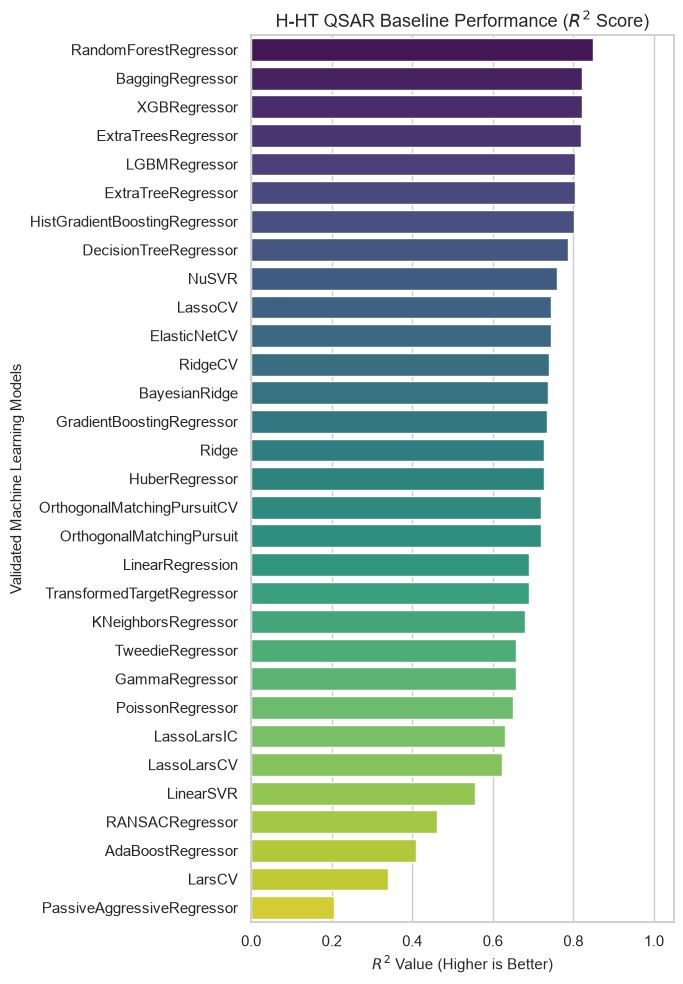

C:\Users\Adnan Habib\AppData\Local\Temp\ipykernel_8656\3286461199.py:36: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


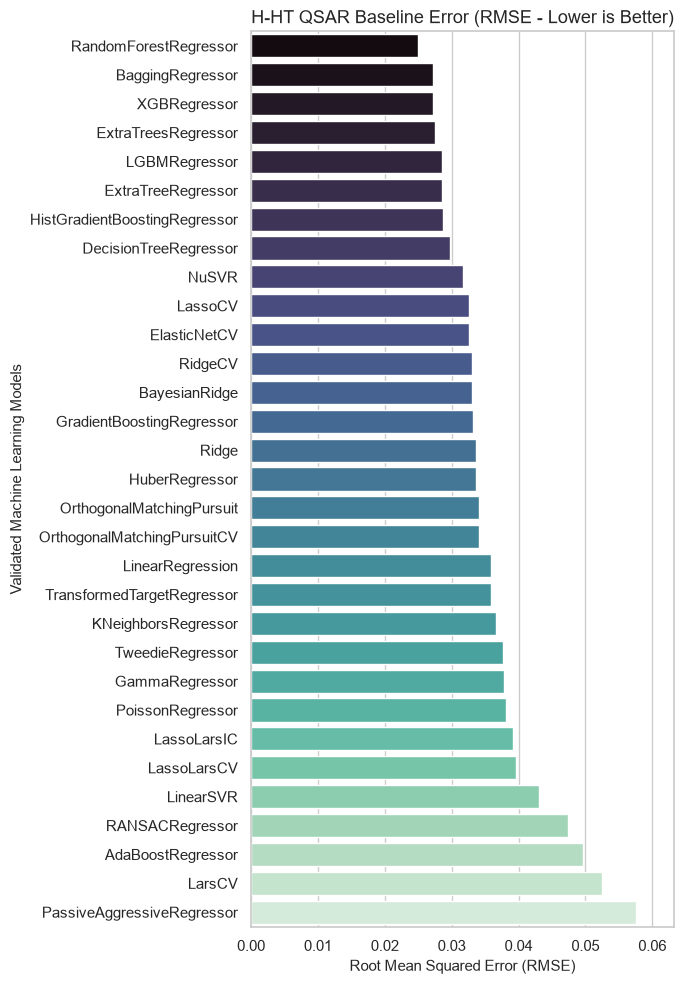

C:\Users\Adnan Habib\AppData\Local\Temp\ipykernel_8656\3286461199.py:48: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


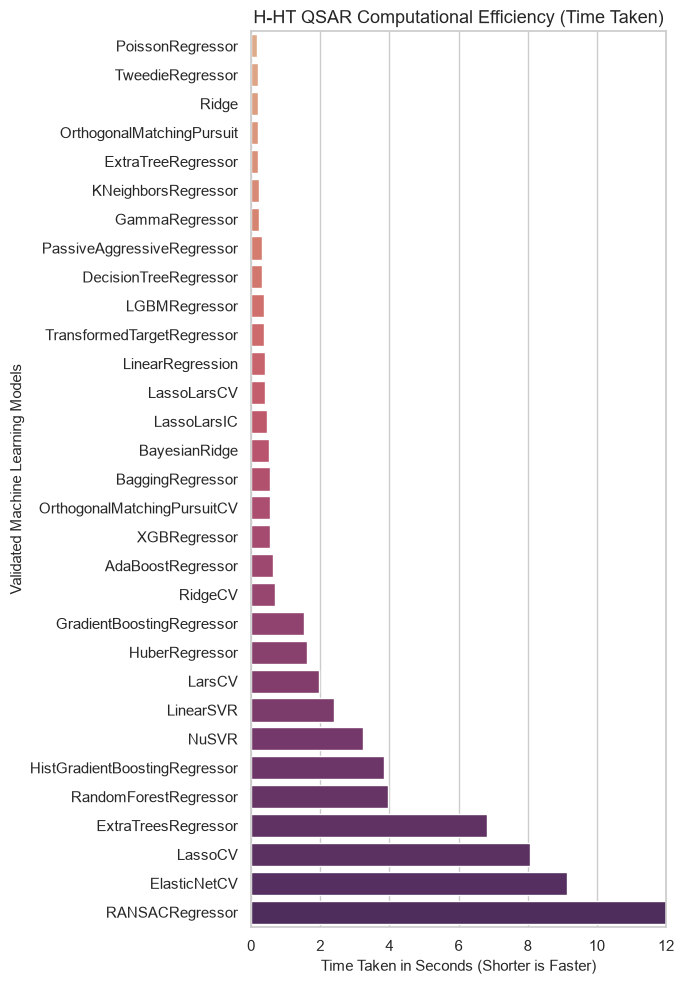

In [28]:
# 1. Plot the Filtered R-Squared graph
plot_lazy_metrics(models, metric="R-Squared")

# 2. Plot the RMSE graph
plot_lazy_metrics(models, metric="RMSE")

# 3. Plot the Execution Time graph
plot_lazy_metrics(models, metric="Time Taken")

In [ ]:
######################################################################
##  H-HT                                                            ##
##                                                                  ##
##                                                                  ##
######################################################################


High-dimensional dataset (881 features). Some models may be slow or fail. Consider dimensionality reduction.


Features shape (Exclusions Active): (2856, 881)
Target Vector shape: (2856,)

Benchmarking filtered baseline models for BBB...

Success! Filtered results saved to 'lazy_regressor_bbb_filtered_performance.csv'

=== FILTERED PERFORMANCE SUMMARY ===
                               Adjusted R-Squared  R-Squared      RMSE  \
Model                                                                    
LarsCV                                   2.690727   0.082092  0.234774   
KernelRidge                              2.623214   0.118746  0.230039   
PassiveAggressiveRegressor               2.250151   0.321284  0.201880   
LinearSVR                                2.238692   0.327505  0.200953   
MLPRegressor                             2.226309   0.334228  0.199946   
PoissonRegressor                         2.168956   0.365365  0.195215   
TransformedTargetRegressor               2.140487   0.380822  0.192823   
LinearRegression                         2.140487   0.380822  0.192823   
LassoLarsCV  

C:\Users\Adnan Habib\AppData\Local\Temp\ipykernel_8656\1437265144.py:94: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


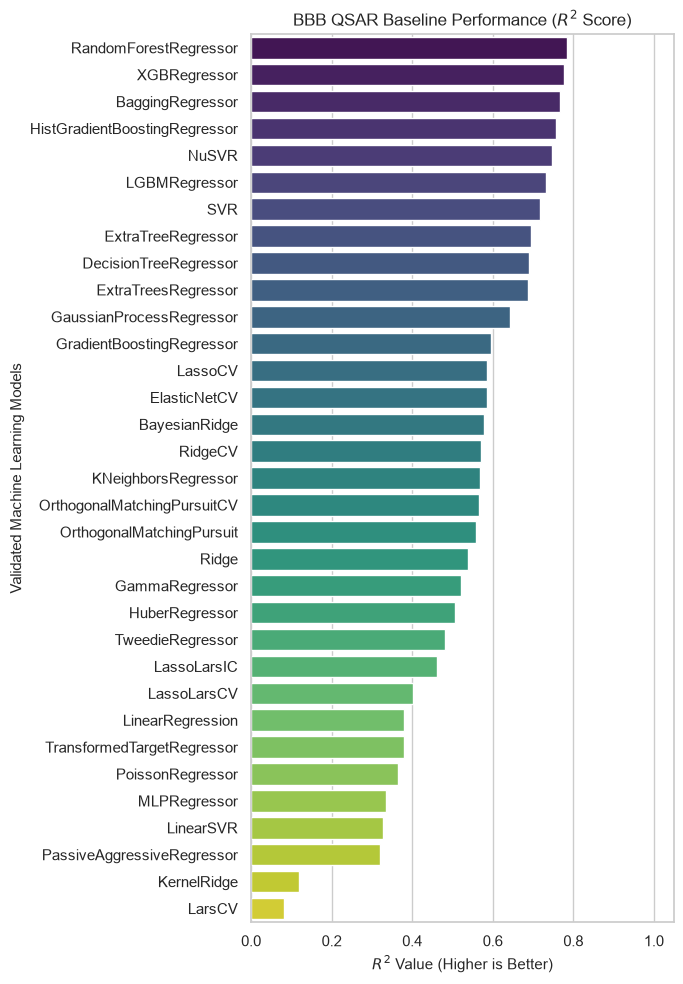

C:\Users\Adnan Habib\AppData\Local\Temp\ipykernel_8656\1437265144.py:103: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


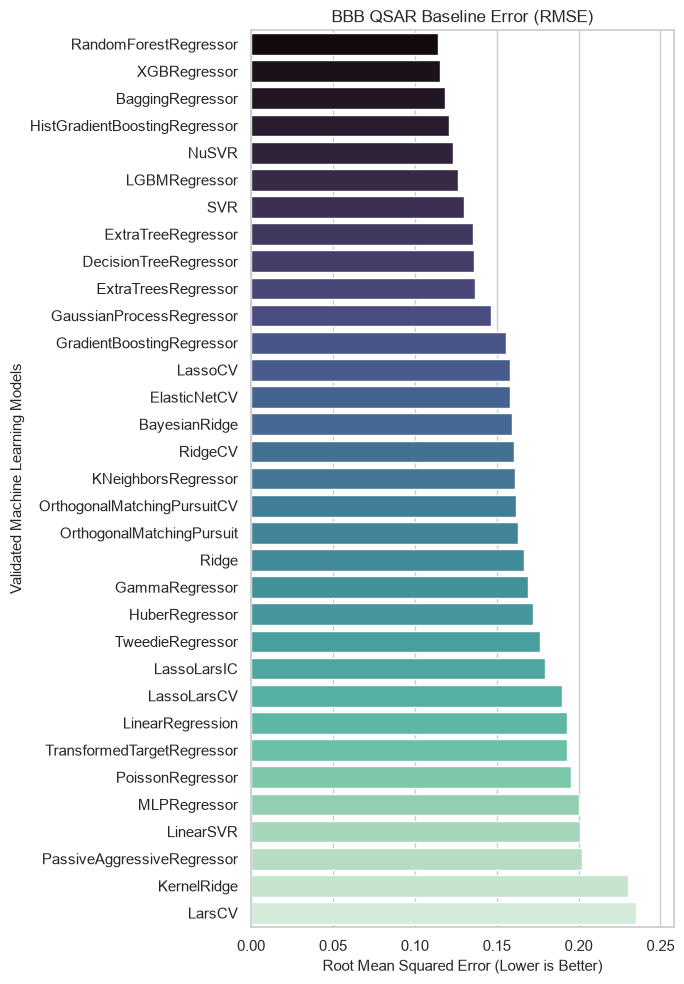

C:\Users\Adnan Habib\AppData\Local\Temp\ipykernel_8656\1437265144.py:113: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


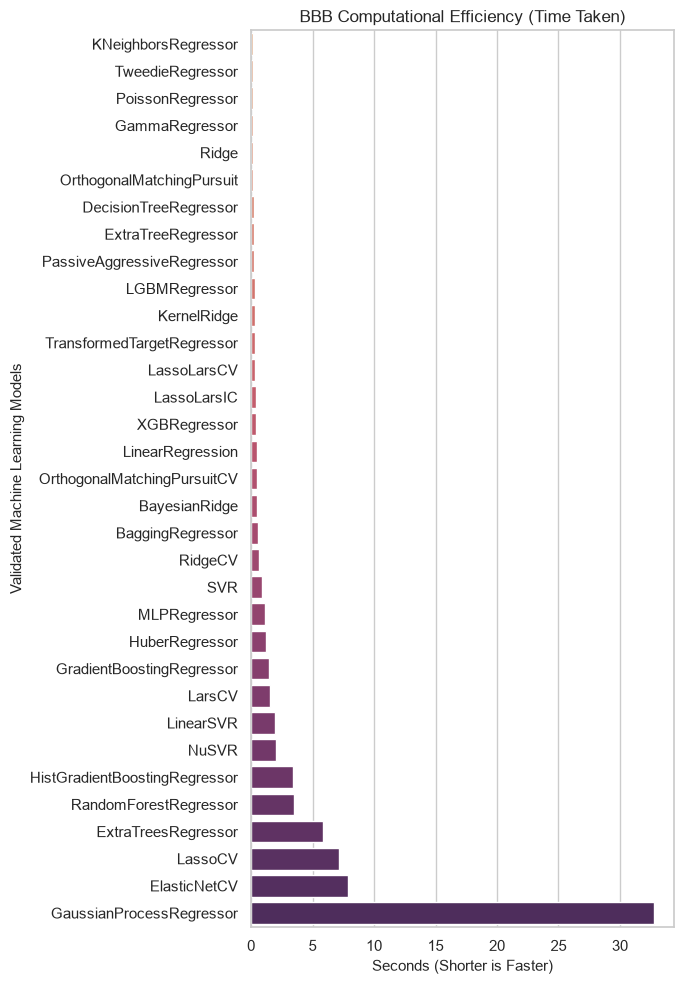

In [38]:
import importlib
import os
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import lazypredict.Supervised
from sklearn.model_selection import train_test_split

# ==========================================
# 1. SPECIFY AND REMOVE YOUR BLACKLISTED MODELS
# ==========================================
# Reload the registry first to start fresh
importlib.reload(lazypredict.Supervised)
from lazypredict.Supervised import LazyRegressor

# Your specified exclusion list
models_to_ignore = [
    "Lars",
    "SGDRegressor",
    "RANSACRegressor",
    "QuantileRegressor",
    "AdaBoostRegressor",
    "ElasticNet",
    "DummyRegressor",
    "LassoLars",
    "Lasso",
]

# Apply filter to the registry
lazypredict.Supervised.REGRESSORS = [
    (name, model)
    for name, model in lazypredict.Supervised.REGRESSORS
    if name not in models_to_ignore
]


# ==========================================
# 2. LOAD DATA & ALIGN TARGET FOR BBB
# ==========================================
descrip = pd.read_csv("PaDEL_descriptors.csv")
df = pd.read_excel("FINAL.xlsx")

target_endpoint = "BBB"
df = df.dropna(subset=["SMILES", target_endpoint])

# Reset indices for safe structural matching
df = df.reset_index(drop=True)
descrip = descrip.reset_index(drop=True)

# Separate features matrix and target vector
X = descrip.drop(columns=["Name"]) if "Name" in descrip.columns else descrip.copy()
X = X.apply(pd.to_numeric, errors="coerce").fillna(X.mean())
y = df[target_endpoint].values

print(f"Features shape (Exclusions Active): {X.shape}")
print(f"Target Vector shape: {y.shape}")

# Split into 80% train and 20% validation test data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)


# ==========================================
# 3. RUN LAZYREGRESSOR & SAVE
# ==========================================
print(f"\nBenchmarking filtered baseline models for {target_endpoint}...")
reg = LazyRegressor(verbose=0, ignore_warnings=True, custom_metric=None)
models, predictions = reg.fit(X_train, X_test, y_train, y_test)

# Save the filtered benchmark to a clean CSV
output_filename = "lazy_regressor_bbb_filtered_performance.csv"
models.to_csv(output_filename)
print(f"\nSuccess! Filtered results saved to '{output_filename}'")
print("\n=== FILTERED PERFORMANCE SUMMARY ===")
print(models)


# ==========================================
# 4. UNIFIED PLOTTING ENGINE
# ==========================================
def plot_lazy_metrics(df_models, endpoint_name, metric="R-Squared"):
    """Generates clean performance visualizations for the selected QSAR endpoint."""
    sns.set_theme(style="whitegrid")
    plt.figure(figsize=(7, 10))
    df_plot = df_models.copy()

    # Drop any remaining negative R2 values to keep scale scannable
    if "R-Squared" in df_plot.columns:
        df_plot = df_plot[df_plot["R-Squared"] > 0]

    if metric == "R-Squared":
        df_plot = df_plot.sort_values(by="R-Squared", ascending=False)
        ax = sns.barplot(
            y=df_plot.index, x="R-Squared", data=df_plot, palette="viridis"
        )
        ax.set(xlim=(0, 1.05))
        plt.title(f"{endpoint_name} QSAR Baseline Performance ($R^2$ Score)")
        plt.xlabel("$R^2$ Value (Higher is Better)", fontsize=11)

    elif metric == "RMSE":
        df_plot = df_plot.sort_values(by="RMSE", ascending=True)
        ax = sns.barplot(
            y=df_plot.index, x="RMSE", data=df_plot, palette="mako"
        )
        max_rmse = df_plot["RMSE"].max() if not df_plot.empty else 1.0
        ax.set(xlim=(0, max_rmse * 1.1))
        plt.title(f"{endpoint_name} QSAR Baseline Error (RMSE)")
        plt.xlabel("Root Mean Squared Error (Lower is Better)", fontsize=11)

    elif metric == "Time Taken":
        df_plot = df_plot.sort_values(by="Time Taken", ascending=True)
        ax = sns.barplot(
            y=df_plot.index, x="Time Taken", data=df_plot, palette="flare"
        )
        max_time = df_plot["Time Taken"].max() if not df_plot.empty else 10.0
        ax.set(xlim=(0, max_time * 1.05))
        plt.title(f"{endpoint_name} Computational Efficiency (Time Taken)")
        plt.xlabel("Seconds (Shorter is Faster)", fontsize=11)

    plt.ylabel("Validated Machine Learning Models", fontsize=11)
    plt.tight_layout()
    plt.show()


# ==========================================
# 5. GENERATE THE VISUALS
# ==========================================
plot_lazy_metrics(models, endpoint_name="BBB", metric="R-Squared")
plot_lazy_metrics(models, endpoint_name="BBB", metric="RMSE")
plot_lazy_metrics(models, endpoint_name="BBB", metric="Time Taken")